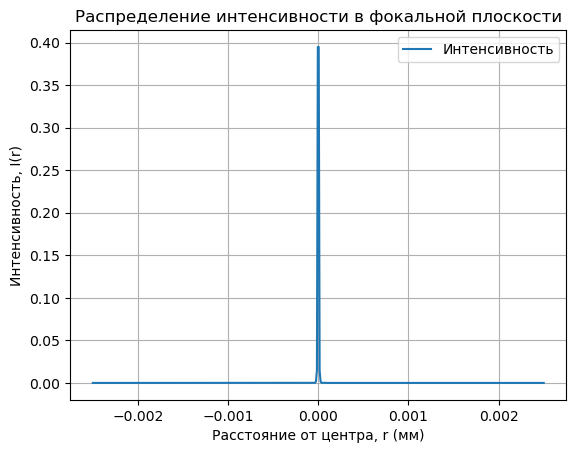

In [3]:
# Step 1. Calculation Imax
geometry = []
def get_Imax():
    sim_empty = mp.Simulation(
        cell_size=cell,
        boundary_layers=pml_layers,
        geometry=geometry,
        sources=sources,
        k_point=sources_obj.get_k_vector(),
        resolution=conf.min_resolution * increase_resolution
    )
        
    # Adding a near2far area
    near2far_region_empty = sim_empty.add_near2far(
        conf.inc_fcen,  # центральная частота
        conf.inc_df,      # ширина спектра
        conf.inc_nfreq, # дискретность частот
        mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=Y_cell_size)),
    )
    
    # Running the simulation
    conf.end_time(sim_empty,angle)
    

    ff_res = conf.resolution_base/Y_cell_size # resolution of the calculated field
    
    # Calculating fields in the far zone. Focal Plane
    far_field_front = sim_empty.get_farfields(
        near2far_region_empty,
        ff_res,
        center=mp.Vector3(x=conf.flux_center[0] + f),
        size = mp.Vector3(y=Y_cell_size)
    )
    
    I_front_array = abs(far_field_front["Ez"])**2
    I0 = np.mean(I_front_array)
    Imax = I0 * Y_cell_size**4/ (4 * 1.22**2 * conf.inc_wavelength**2 * f**2)
    sim_empty.reset_meep()
    return Imax, I0

    
Imax, I0 = get_Imax()